In [1]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #02 - Successive Corrections

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using successive corrections.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [2]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles

import pandas as pd

In [3]:
### Create function for Cressman Analysis ###
def cressman(dist: float, roi: float) -> float:
    """
    Function to analyze the value at a given point from other data
    using a Cressman analysis technique.
    
    inputs:
      dist = distance between the analysis point and the observation point
      roi = the radius of influence 
      
    returns:
      out = value of the Cressman weight function
    """
    out = 0
    if(dist <= roi):
      num = (roi ** 2) - (dist ** 2)
      denom = (roi ** 2) + (dist ** 2)
      out = num / denom

    return out

In [ ]:
### Create function for bilinear interpolation ###

def toIndexSpace(x: np.ndarray or float, x0: float) -> np.ndarray or float:
    delta = .0127
    return ( (x - x0) / delta )

def bilinearInterpolate(xo: float, yo: float, xGrid: np.ndarray, yGrid: np.ndarray, analysisArr: np.ndarray) -> float:
    '''Take an observation point and calculate the analysis value there with bilinear interpolation using the nearest four analysis points. See cell below for equation.'''


    # Defining the values at the origin of index space
    x0 = .25
    y0 = -.155

    # Transform the grid of analysis points into index space
    xIndices = toIndexSpace(xGrid, x0)
    yIndices = toIndexSpace(yGrid, y0)

    # Transform the observation point into index space
    xoIndex = toIndexSpace(xo, x0)
    yoIndex = toIndexSpace(yo, y0)

    # Calculate the x- and y-indices of the four points surrounding the observation point
    x1 = int(np.floor(xoIndex))
    x2 = int(np.ceil(xoIndex))
    y1 = int(np.floor(yoIndex))
    y2 = int(np.ceil(yoIndex))

    # Use the indices to find the analysis values at the four analysis points
    tlVal = analysisArr[x1][y1]
    trVal = analysisArr[x2][y1]
    blVal = analysisArr[x1][y2]
    brVal = analysisArr[x2][y2]

    # Construct the component matrices of the matrix-form bilinear interpolation equation (see the cell below)
    matX = np.array([x2 - xoIndex, xoIndex - x1])
    matQ = np.array([[tlVal, trVal], [brVal, blVal]])
    matY = np.array([[y2 - yoIndex], [yoIndex - y1]])

    # Calculate the analysis value at the observation point with some matrix multiplications (and an index because it returns a 1x1 numpy array and I want a float !!!)
    output = (matX @ matQ @ matY)[0]
    
    return output



The bilinear interpolation equation is 
$$
f(x,y) = \frac{1}{(x_2 - x_1)(y_2 - y_1)}
\begin{bmatrix}
x_2 - x & x - x_1
\end{bmatrix}
\begin{bmatrix}
f(Q_{11}) & f(Q_{12}) \\
f(Q_{21}) & f(Q_{22})
\end{bmatrix}
\begin{bmatrix}
y_2 - y \\
y - y_1
\end{bmatrix},
$$
courtesy of Wikipedia. All $x$- and $y$-values are put into index space before use in the equation.
We omit the fraction at the beginning because the denominator evaluates to 1 (an advantage of index space), so the whole fraction reduces to 1.

In [5]:
### Read in observations ###

# SID LAT LON HGT DIR SPD
# 0   1   2   3   4   5

# I think you'll have to change this if you're grading on a non-UNIX machine... sorry
observation_file = r"../RAOBs_201903131200.txt"


# This reads the data as comma-separated values, creating a pandas dataframe that is subsequently converted into a numpy array for easy manipulation later.
# Oh and it has no headers, which also makes things easier later.
observations = pd.read_csv(observation_file, header=None).to_numpy()

print(observations[:,3].shape)

(135,)


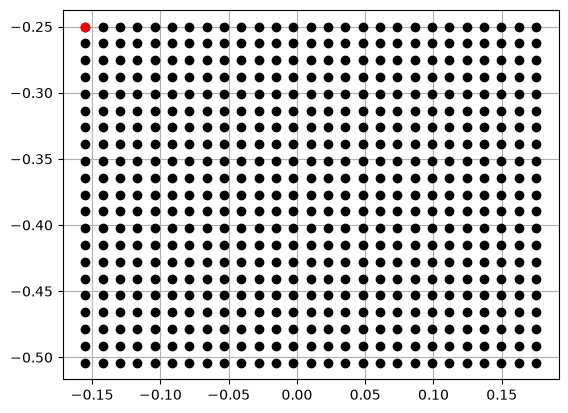

In [6]:
### Set up analysis map with a 21x27 rectangular grid of points ###
''' We have a polar stereographic projection with a standard latitude of 60degN and a standard latitude of 100degW. Map scale is 1/15,000,000. 
    We need our origin at 90degN latitude and 0deg longitude, with grid points every 1.27cm extending to x = +- 25cm and y = +- 15.5cm.
    The first array member (0,0) is supposed to be at x = 25cm, y = -15.5cm.
'''

#np array element format: array[col][row], both starting at zero

# Init lists of x- & y-values
x = []
y = []

# x- & y-values at (0,0)
x0 = .25
y0 = -.155

# Populating the x & y lists with all the values on the grid
# You will note that all cm values have been converted to m
for i in range(27):
    diff = i * .0127
    if(i < 21):
        x.append(x0 + diff)
    y.append(y0 + diff)

x = np.array(x)
y = np.array(y)

# Use the x- & y-values to populate two new numpy arrays with the values necessary to actually graph all gridpoints
gridx, gridy = np.meshgrid(x,y)

testx = [-.25]
testy = [-.155]

# Plot the grid of values, to ensure that we made it correctly
fig, ax = plt.subplots()
ax.plot(gridy, -gridx, marker='o', color='k', linestyle='none')
ax.plot(testy, testx, marker='o', color='r', linestyle='none')
ax.grid()
plt.show()


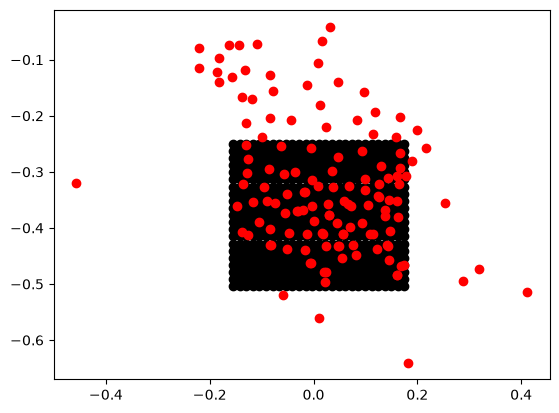

In [7]:
### convert obs lat/long to x,y ###

# Conversion factor we need cuz numpy trig fcns are in radians
degToRad = np.pi / 180

# Defining our standard latitude & longitude
standardLat = 60 * degToRad
standardLong = -100 * degToRad

# Earth's mean radius, in meters
rho = 6.371e6

# Map scale
m = 1 / 15e6

# Helper function for calculating scale factor
def __scaleFactor__(lat: float) -> float:
    sigmaNumerator = 1 + np.sin(standardLat)
    sigmaDenominator = 1 + np.sin(lat)

    return (sigmaNumerator / sigmaDenominator)

# Defining a function to convert from lat/long to x/y
def getCartesian(latDeg: float, longDeg: float) -> (float,float):
    lat = latDeg * degToRad
    long = (longDeg * degToRad) - standardLong
    sigma = __scaleFactor__(lat)
    r = m * rho * sigma * np.cos(lat)
    x = r * np.cos(long)
    y = r * np.sin(long)

    return x,y



# Initializing lists for the x- & y-values we will calculate from the observation lat/long
obsx = []
obsy = []

for i in range(observations.shape[0]):
    tempx, tempy = getCartesian(observations[i][1], observations[i][2])
    obsx.append(tempx)
    obsy.append(tempy)

# Turning lists into np arrays because they're much nicer to work with
obsx = np.array(obsx, dtype=np.double)
obsy = np.array(obsy, dtype=np.double)

# Check points with a graph
fig, ax = plt.subplots()
ax.plot(gridy, -gridx, marker='o', color='k', linestyle='none')
ax.plot(obsy, -obsx, marker='o', color='r', linestyle='none')
plt.show()

# The points do appear to be in the correct locations

In [8]:
### Perform 500mb geopotential height analyses using a Cressman weighting Function###
#Use radii of influence 4, 2.5, 1.5 *dmin

def analyze(xa: float, ya: float, xArr: np.ndarray, yArr: np.ndarray, obsArr: np.ndarray, roi: float, bgArr: np.ndarray, bgVal: float or None, first=False) -> float:
    '''
    Do a Cressman analysis at point (xa, ya) based on input observations. If no background is provided, the analysis runs without one using an alternate analysis function. 
    '''
    
    # Make arrays of the (signed) x- & y-distance between the analysis point and the observation points in the RoI
    xDist = xa - xArr
    yDist = ya - yArr
    
    # Initialize an empty np array that will be filled with the weights
    weights = np.ndarray((obsArr.shape[0],))

    # Populate the weights array using the cressman function we defined waaay back at the beginning
    for i in range(obsArr.shape[0]):
        dist = np.hypot(xDist[i], yDist[i])
        # print(dist)
        weights[i] = cressman(dist, roi)

    # Initializing a couple variables that get their real value in a conditional later
    num = 0
    firstTerm = 0
    # Pick the right analysis function based on whether this is the first iteration or not
    if(first):
        # First-iteration numerator is only the sum of the weighted observations
        num = (weights * obsArr).sum()
    else:
        # Later-iteration numerators are the sum of the weighted observation increments
        bgArr = np.nan_to_num(bgArr)
        num = (weights * (obsArr - bgArr)).sum()
        # Also, we now have to add the background value to our analysis
        firstTerm = bgVal
    
    # Define the denominator of the fraction in the analysis function
    denom = weights.sum()

    # Finally evaluate the analysis function and return it
    output = firstTerm + (num / denom)

    return output

def getdmin(x: np.ndarray, y: np.ndarray) -> float:
    # For each point provided, calculate the smallest distance to any other point, then average all of them.
    
    # Create an array of all the observation points, then transpose it so it's actuall a column vector
    points = np.array([x,y]).T

    # Create an empty array that we will fill with distances as we calcuate
    minimumDistances = np.ndarray((points.shape[0], ))
    nearests = np.ndarray((points.shape[0], ))

    # Iterate over all points i
    for i in range(points.shape[0]):
        # Initialize the minimum distance variable with an absurd number so that all the distances are less than it
        minDist = 1e100
        nearest = -1

        # Iterate over all points j 
        for j in range(points.shape[0]):
            # The distance between a point and itself is zero so we skip it
            if(i == j):
                continue
            # Calculate the distance between point i and point j
            # print(points[i],points[j])
            dist = np.hypot(points[i][0] - points[j][0], points[i][1] - points[j][1])


            # If the distance between i and j is less than the current minimum distance, replace the current minimum distance with the distance between i and j
            if(dist < minDist):
                minDist = dist
                nearest = j


        minimumDistances[i] = minDist
        nearests[i] = j

    # Take the average of the minimum distances 
    dmin = minimumDistances.mean()
    return dmin


print(getdmin(obsx, obsy))
# print(analyze(x[0],y[0], obsx, obsy, observations[:,3], roi, None, None, first=True))

0.025548700820071418


In [9]:
### First analysis, no successive corrections ###

# Define our radii of influence
dmin = getdmin(obsx, obsy)
roi1 = 4 * dmin
roi2 = 2.5 * dmin
roi3 = 1.5 * dmin

# Create a list that will be populated with analysis values, and lists for the lat/long of each analysis point for when we write to a file
analysis1 = []
lats1 = []
longs1 = []
graphZ1 = np.ndarray((len(x), len(y)))

# Calculate the analysis value at each analysis point
# Also note the lat/long of each point
for i in range(len(x)):
    for j in range(len(y)):
        currVal = analyze(x[i], y[j], obsx, obsy, observations[:,3], roi1, bgArr=None, bgVal=None, first=True)
        analysis1.append(currVal)
        lats1.append(observations[i][1])
        longs1.append(observations[j][2])
        graphZ1[i][j] = currVal

# Convert the analysis list into a fixed-size numpy array for easier calculation later
# Convert the lat/long lists to numpy arrays so we can make a dataframe
analysis1 = np.array(analysis1)
lats1 = np.array(lats1)
longs1 = np.array(longs1)

# Converting analysis & lat/long to a writeable dataframe
output1 = np.array([lats1, longs1, analysis1]).T
output1 = pd.DataFrame(output1)

# Write to disk
output1.to_csv("AnalysisPass1.csv", index=False, header=False)

print(roi1)


0.10219480328028567


In [10]:
### Next Analyses ###

def isOutsideGrid(x: float, y: float) -> bool:
    '''Determine whether a point is inside or outside the bounds of the analysis grid. Returns True if the point is OUTSIDE the grid.'''
    return (x < .25) or (x > .504) or (y < -.155) or (y > .1752)


def backgroundFromAnalysis(analysis: np.ndarray, roi: float) -> np.ndarray:
    '''Take a set of analysis values and use them to generate background values at each observation point'''
    background = []
    for i in range(len(obsx)):

        if(isOutsideGrid(obsx[i],obsy[i])):
            # If the observation point is outside the analysis grid, we interpolate with the Cressman function
            bgVal = analyze(obsx[i], obsy[i], gridx.flatten(), gridy.flatten(), analysis1, roi, bgArr=None, bgVal=None, first=True)
        else:
            bgVal = bilinearInterpolate(obsx[i], obsy[i], x, y, analysis)
        background.append(bgVal)
    background = np.array(background)

    return background

a1background = backgroundFromAnalysis(graphZ1, roi1)

analysis2 = []
graphZ2 = np.ndarray((len(x), len(y)))


for i in range(len(x)):
    for j in range(len(y)):
        currBgInd = (27 * i) + j
        currBgVal = analysis1[currBgInd]
        currVal = analyze(x[i],y[j], obsx, obsy, observations[:,3], roi2, a1background, currBgVal)
        analysis2.append(currVal)
        graphZ2[i][j] = currVal

analysis2 = np.array(analysis2)

a2background = backgroundFromAnalysis(graphZ2, roi2)

analysis3 = []
graphZ3 = np.ndarray((len(x), len(y)))

for i in range(len(x)):
    for j in range(len(y)):
        currBgInd = (27 * i) + j
        currBgVal = analysis2[currBgInd]
        currVal = analyze(x[i],y[j], obsx, obsy, observations[:,3], roi3, a2background, currBgVal)
        analysis3.append(currVal)
        graphZ3[i][j] = currVal

analysis3 = np.array(analysis3)

a3background = backgroundFromAnalysis(graphZ3, roi3)


/tmp/ipykernel_7566/2025973233.py:40: RuntimeWarning: invalid value encountered in scalar divide
  output = firstTerm + (num / denom)


In [ ]:
### Calculate Analysis Differences

diff31 = graphZ3 - graphZ1
diff32 = graphZ3 - graphZ2
diff21 = graphZ2 - graphZ1


# Initialize lists that will be used for calculating root-mean-squared values
backgrounds = [a1background, a2background, a3background]
rms = []


# Calculate the RMS value for each background analysis pass
# I can't do this one with array operations because there are NaNs in the bg arrays and I can't get NumPy to play nice
# nan_to_num doesn't work cuz the NaNs are replaced with 0 so obs - bg is like, 5000, which is absurd. I could replace them with like, the mean of the analysis vals, but that feels too approximate
# I tried masked arrays but for some reason they won't work with division, so we're just doing it manually
# All I want for Christmas is a functional language with native array ops
for bg in backgrounds:
    obs = observations[:,3]
    sum = 0
    nans = 0
    for i in range(len(obs)):
        if(np.isnan(bg[i])):
            nans += 1
        else:
            sum += (obs[i] - bg[i]) ** 2
    rms.append( np.sqrt(sum / (len(obs) - nans)) )


# Print the RMS values neatly :)
for r in range(len(rms)):
    print(f'RMS {r + 1}: ', rms[r])

RMS 1:  144.8637029680017
RMS 2:  123.55595188679145
RMS 3:  80.94953956621025


In [72]:
test = np.array([1,2,3,4,5,6])
mest = np.ma.array(test, mask=[True, True, False, False, True, True])

print(np.ma.count(mest))

2


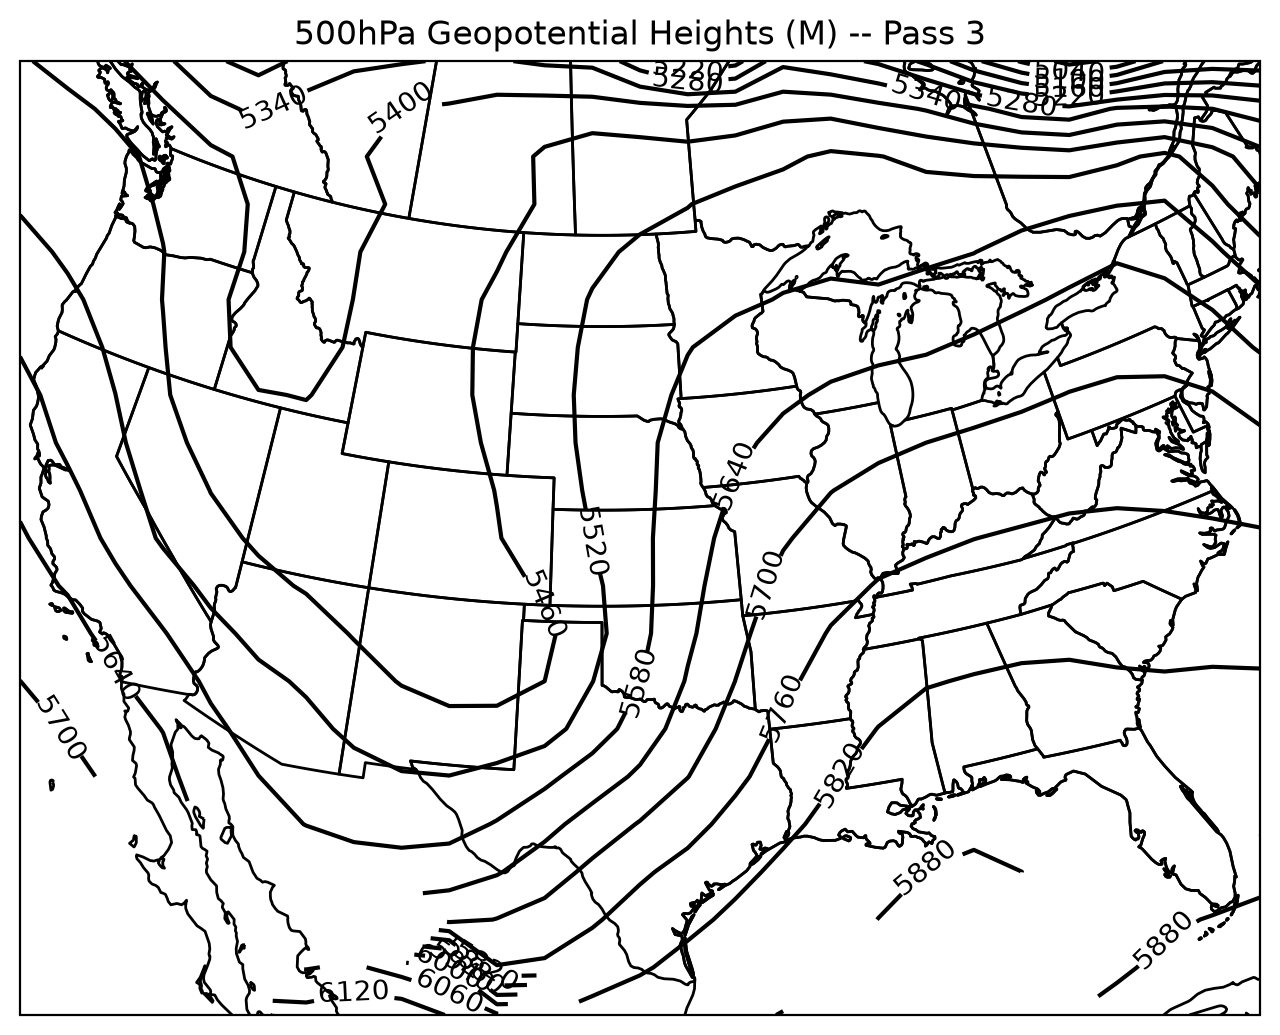

In [25]:
### Plot 500mb analyses over a map ###

# CartoPy throws a fit if I don't include this
import os
os.environ["PROJ_IGNORE_CELESTIAL_BODY"] = "YES"

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=-100,central_latitude=90,true_scale_latitude=60,globe=globe)
fig = plt.figure(figsize=(8,8),dpi=200)
ax1 = fig.add_subplot(111,projection=proj)
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot analysis (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
cs1 = ax1.contour(gridy/100/m,-gridx/100/m,graphZ3.T,colors='k',levels=np.arange(0,8000,60),transform=proj)
plt.clabel(cs1,levels=np.arange(0,8000,60))

ax1.set(title='500hPa Geopotential Heights (M) -- Pass 3')

plt.show()

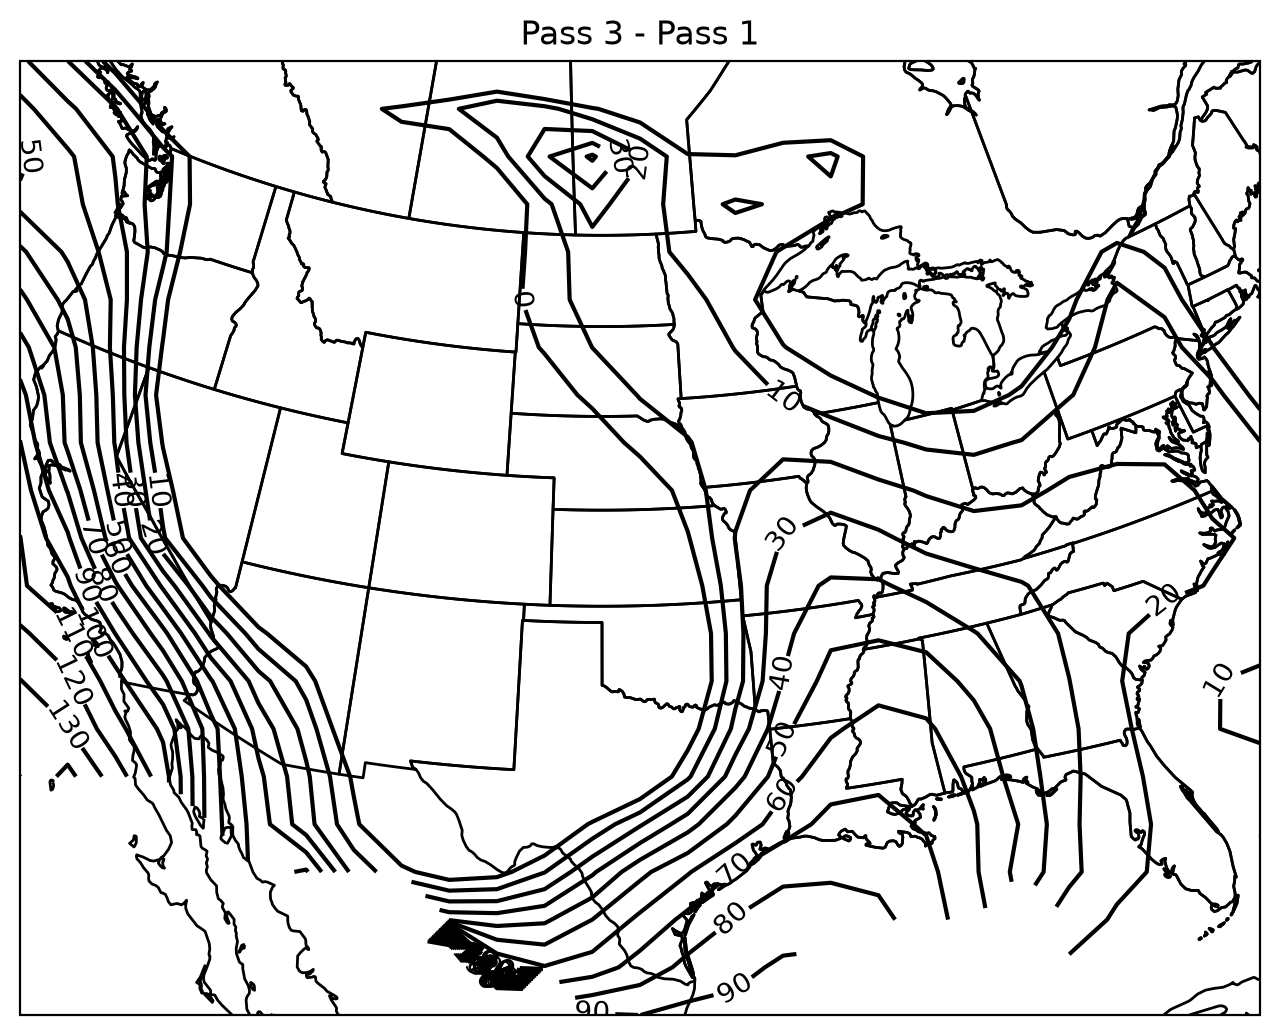

In [15]:
### Plot Analysis Differences ###
#use old code...
import os
os.environ["PROJ_IGNORE_CELESTIAL_BODY"] = "YES"

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=-100,central_latitude=90,true_scale_latitude=60,globe=globe)
fig = plt.figure(figsize=(8,8),dpi=200)
ax1 = fig.add_subplot(111,projection=proj)
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot analysis (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
cs1 = ax1.contour(gridy/100/m,-gridx/100/m,diff31.T,colors='k',levels=np.arange(0,200,10),transform=proj)
plt.clabel(cs1,levels=np.arange(0,200,10))

ax1.set(title='Pass 3 - Pass 1')

plt.show()

In [ ]:
### Store the analyses in text files ###

# I already did!!!!
# You gotta put this stuff higher up

In [ ]:
### Store the difference fields in text files ###


In [ ]:
### Store RMS values in text file ###


In [ ]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.
    

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    

3 - What happens as you increase the number of successive correction passes?  Is this 
    desirable?  Why or why not?
    

'''

1. The analysis appears quite similar to the one we did with function fitting. There is a large trough from BC to northern NM. The geopotential gradient appears steepest over the OK-TX border. I'm not good enough at weather charts to be sure about any other features. The isohypses from the UP into central ON are wobbly like there's something goin on there, but pushing farther into Canada gets more distorted so I don't know how trustworthy it is. I think the distortion on the NE and SW periphery of the map are probably due to the sparseness of observations along with the fact that we start to go outside the analysis grid there.

2. "Smoother" analysis are those that show large-scale features without many small-scale features that make the contours wobbly and sharply-curved. A property of the Method of Successive Corrections is that small-scale features converge more slowly than large-scale features. We would therefore expect the first analysis to be the smoothest, and this is indeed what we observe. Additionally, we use smaller radii of influence with each pass, which will also increase the effect of smaller features. 

3. With more passes, the analysis slowly converges to the observation value at observation points. This isn't what we want, because the observation value includes errors. Instead, we need to strike a balance: enough passes to capture all the significant large- and small-scale features, but not so many that we are starting to fit to error.